## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch
from sklearn.manifold import TSNE

# dataset helper
from helper import get_wl_point_obs, plot_shred_reconstruction, extract_water_level_measurements, align_ds

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import ROMDataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.train import lagged_fit, lagged_evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

np.random.seed(42)

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

# read datasets
ds = dfs.read()
dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

del dfs

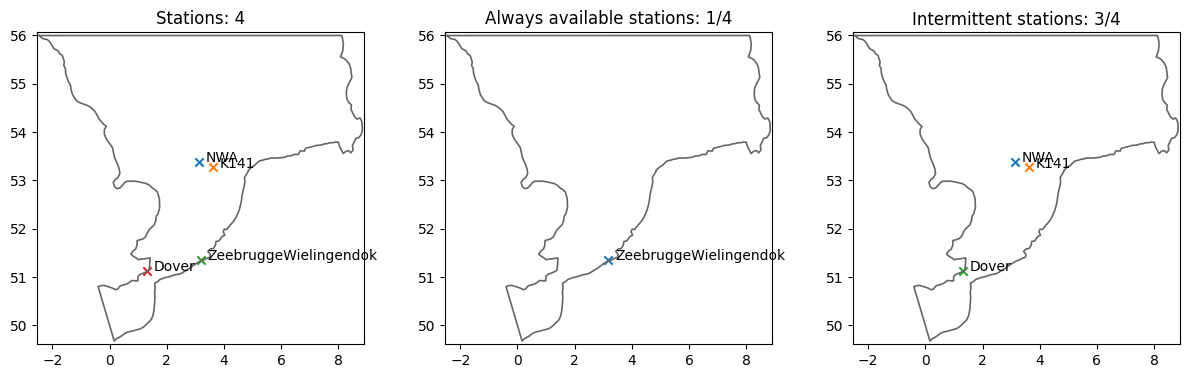

In [4]:
# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
hf = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]
alllist = [s for s in alllist if s.name in hf]

stations = []
available_stations = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        available_stations.append(alllist[i])
    else:
        intermittent.append(alllist[i])

# extract water level measurements for all stations
measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(available_stations, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(available_stations)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")
plt.tight_layout()
plt.show()


In [5]:
# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in available_stations]
measurements_av = measurements[:, av_indices]

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)
print("Always-available measurements shape:", measurements_av.shape)

# free memory
del dsH, dsU, dsV
del ds

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 4])
Always-available measurements shape: torch.Size([35039, 1])


## ROM training

In [6]:
# Assuming 30 days per month, 24 hours per day, and measurements every 30 minutes (2 per hour)
lenmonths = (30 * 24 * 2)  
nmonths = H.shape[0] // lenmonths 
ntime_keeped = nmonths * lenmonths 
print(f"Time keeprd: {ntime_keeped}/{H.shape[0]} total steps ({nmonths} months) -> coverage: {100*ntime_keeped/H.shape[0]:.1f}% \n")

# reshape the arrays to (nmonths, lenmonths, nfeatures) for training
H = H[:ntime_keeped].reshape(nmonths, lenmonths, -1)
U = U[:ntime_keeped].reshape(nmonths, lenmonths, -1)
V = V[:ntime_keeped].reshape(nmonths, lenmonths, -1)
measurements = measurements[:ntime_keeped].reshape(nmonths, lenmonths, -1)
measurements_av = measurements_av[:ntime_keeped].reshape(nmonths, lenmonths, -1)    

print("Reshaped H shape:", H.shape)
print("Reshaped U shape:", U.shape)
print("Reshaped V shape:", V.shape)
print("Reshaped measurements shape:", measurements.shape)
print("Reshaped measurements shape:", measurements_av.shape)

#permute the months 
permuted_indices = np.random.permutation(nmonths)
H = H[permuted_indices]
U = U[permuted_indices]
V = V[permuted_indices]
measurements = measurements[permuted_indices]
measurements_av = measurements_av[permuted_indices]

print("\npermutation indices:", permuted_indices)

Time keeprd: 34560/35039 total steps (24 months) -> coverage: 98.6% 

Reshaped H shape: torch.Size([24, 1440, 8532])
Reshaped U shape: torch.Size([24, 1440, 8532])
Reshaped V shape: torch.Size([24, 1440, 8532])
Reshaped measurements shape: torch.Size([24, 1440, 4])
Reshaped measurements shape: torch.Size([24, 1440, 1])

permutation indices: [ 8 16  0 18 11  9 13  1 21  5  2 12 15  3  4 22 17 20 23  7 10 14 19  6]


## Hyperparameters and tuning

In [7]:
ERRORS = []

# DataManager
LAGS = 48               # number of past time steps to use as input for the model (e.g., 48 for 24 hours of data at 30-minute intervals)

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 150        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 30           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Default configuration used by the training cells below
W_FACTOR = 0.8              # weight factor for the loss function (if using a weighted loss)
W_KEEPED_TIMESTEPS = 16      # number of past time steps to keep in the loss function when using a weighted loss (if applicable)

# Architecture
ENCODER_DEPTH = 2              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

In [8]:
# Lagged-loss tuning grid
W_FACTOR_GRID = np.round(np.arange(0.2, 0.9, 0.1), 2).tolist()  # [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
W_KEEPED_TIMESTEPS_GRID = np.arange(4, 21, 4).tolist()  # [4, 8, 12, 16, 20]

LAGGED_LOSS_TUNING_GRID = [
    {"w_factor": w_factor, "w_keeped_timesteps": w_keeped_timesteps}
    for w_factor in W_FACTOR_GRID
    for w_keeped_timesteps in W_KEEPED_TIMESTEPS_GRID
]

print("Lagged-loss tuning grid, total configurations:", len(LAGGED_LOSS_TUNING_GRID))
print("Expected total times (15 min per config) -> total expected time: ", len(LAGGED_LOSS_TUNING_GRID)*15, "minutes (", len(LAGGED_LOSS_TUNING_GRID)*15/60, "hours )\n")

Lagged-loss tuning grid, total configurations: 35
Expected total times (15 min per config) -> total expected time:  525 minutes ( 8.75 hours )



## Normal training

In [9]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 26393

Data shapes after preparation:
Train:	 torch.Size([27360, 48, 4]) -> torch.Size([27360, 120])
Val:	 torch.Size([2880, 48, 4]) -> torch.Size([2880, 120])
Test:	 torch.Size([4320, 48, 4]) -> torch.Size([4320, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  48%|████▊     | 72/150 [09:32<10:19,  7.95s/it, Train Loss=0.00371, Val Loss=0.00582, Patience=29, Best Val Loss=0.00535, LR=5.21e-04]

Early stopping at epoch 73
Training completed with best validation loss: 0.0053


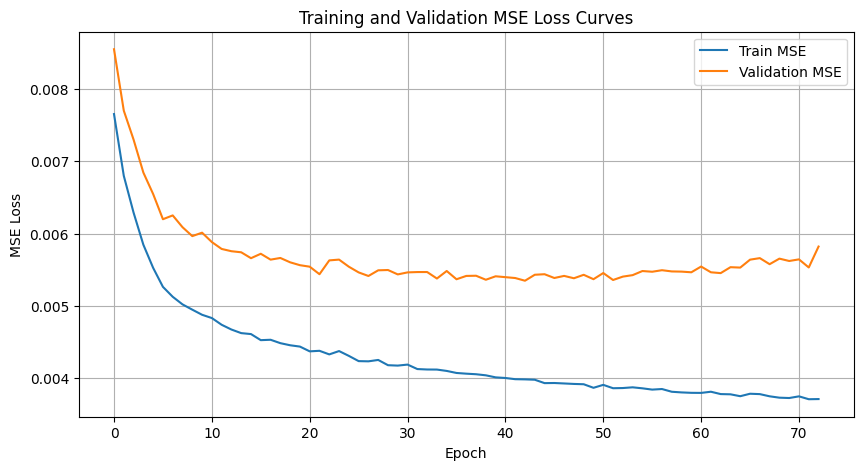

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,Normal_training,0.003986,0.005349,0.003318,0.127359,0.136852,0.119124


In [10]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels = True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset, 
    model = f"(mSHRED): TR+{DECODER}", type="Normal_training", masking_type=MASKING_TYPE,
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

normal_shred = mshred

## Lagged training

In [12]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, pad_output=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1] 
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 26393

Data shapes after preparation:
Train:	 torch.Size([27360, 48, 4]) -> torch.Size([27360, 48, 120])
Val:	 torch.Size([2880, 48, 4]) -> torch.Size([2880, 48, 120])
Test:	 torch.Size([4320, 48, 4]) -> torch.Size([4320, 48, 120])

Input shape for the model: 4
Output shape for the model: 120


In [13]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels = True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, decoder_3D = True
)
mshred = mSHRED(args=model_args).to(device)

In [14]:
# Use cosine annealing LR schedule
train_errors, valid_errors = lagged_fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, w_factor=W_FACTOR, w_keeped_steps=W_KEEPED_TIMESTEPS, masking_type=MASKING_TYPE,
)

Lagged loss weights (W): 
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.00724068 0.00905085 0.01131357 0.01414196
 0.01767744 0.02209681 0.02762101 0.03452626 0.04315783 0.05394728
 0.0674341  0.08429263 0.10536579 0.13170722 0.16463403 0.20579255]
Starting training...


Training:  45%|████▌     | 68/150 [21:00<25:20, 18.54s/it, Train Loss=0.00374, Val Loss=0.00553, Patience=29, Best Val Loss=0.00526, LR=5.63e-04]

Early stopping at epoch 69
Training completed with best validation loss: 0.0053


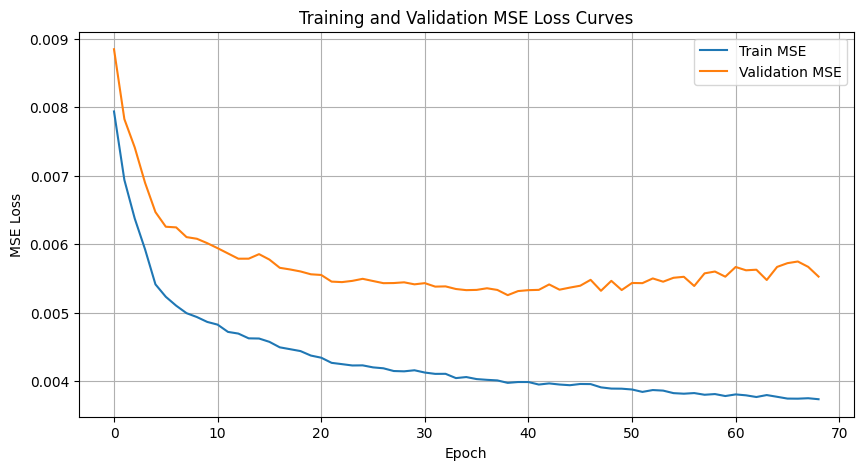

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,Normal_training,0.003986,0.005349,0.003318,0.127359,0.136852,0.119124
1,(mSHRED): TR+cnn,Lagged_training,0.003976,0.005256,0.003307,0.127170,0.136545,0.118986


In [15]:
# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    lagged_evaluate, mshred, train_dataset, val_dataset, test_dataset, 
    model = f"(mSHRED): TR+{DECODER}", type="Lagged_training", masking_type=MASKING_TYPE,
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

lagged_shred = mshred

## Embedding comparison

In [39]:
def get_embeddings(model, dataset, device, n_samples=200):
    model.eval()
    loader = torch.utils.data.DataLoader(dataset, batch_size=n_samples, shuffle=False)

    if MASKING_TYPE in ["mask_data", "mask_data_random"]:
        x, m, _ = next(iter(loader))
        x = x.to(device)
        m = m.to(device)

        print("Input batch shape:", x.shape)  # (n_samples, lags, input_size)

        with torch.no_grad():
            H = model.encoder(x,m)

    else:
        x, _ = next(iter(loader))
        x = x.to(device)

        print("Input batch shape:", x.shape)  # (n_samples, lags, input_size)

        with torch.no_grad():
            H = model.encoder(x)

    return H.cpu().numpy()

def plot_temporal_embeddings(H_normal, H_lagged, n_samples=5, n_dims=4, supervision_t=W_KEEPED_TIMESTEPS):
    lags = H_normal.shape[1]

    fig, axes = plt.subplots(n_samples, n_dims, figsize=(4.5*n_dims, 4.5*n_samples))

    for i in range(n_samples):
        idx = np.random.randint(H_normal.shape[0])

        for d in range(n_dims):
            ax = axes[i, d] if n_samples > 1 else axes[d]

            ax.plot(range(lags), H_normal[idx, :, d], label='Normal', linewidth=2)
            ax.plot(range(lags), H_lagged[idx, :, d], label='Lagged', linewidth=2)

            # ── supervision marker ─────────────────────────
            if supervision_t is not None:
                ax.axvline(
                    x=LAGS-supervision_t,
                    color='black',
                    linestyle='--',
                    linewidth=1.5,
                    label='Supervision' 
                )

            ax.set_title(f'Sample {idx} - Latent dim {d}')
            ax.set_xlabel('Time lag')
            ax.set_ylabel('Centered activation')
            ax.legend()

    plt.tight_layout()
    plt.show()

def plot_temporal_embeddings_mean(H_normal, H_lagged, n_dims=4, supervision_t=W_KEEPED_TIMESTEPS):
    
    mean_normal = H_normal.mean(axis=0)
    mean_lagged = H_lagged.mean(axis=0)
    std_normal = H_normal.std(axis=0)
    std_lagged = H_lagged.std(axis=0)
    lags = mean_normal.shape[0]
    n_dims = min(n_dims, mean_normal.shape[1])

    fig, axes = plt.subplots(1, n_dims, figsize=(5 * n_dims, 5), sharey=True)
    if n_dims == 1:
        axes = [axes]

    for d in range(n_dims):
        ax = axes[d]
        ax.plot(range(lags), mean_normal[:, d], label='Normal', linewidth=2)
        ax.fill_between(
            range(lags),
            mean_normal[:, d] - std_normal[:, d],
            mean_normal[:, d] + std_normal[:, d],
            alpha=0.2,
            label='Normal ±1 std',
        )
        ax.plot(range(lags), mean_lagged[:, d], label='Lagged', linewidth=2)
        ax.fill_between(
            range(lags),
            mean_lagged[:, d] - std_lagged[:, d],
            mean_lagged[:, d] + std_lagged[:, d],
            alpha=0.2,
            label='Lagged ±1 std',
        )

        if supervision_t is not None:
            ax.axvline(
                x=LAGS - supervision_t,
                color='black',
                linestyle='--',
                linewidth=1.5,
                label='Supervision'
            )

        ax.set_title(f'Mean latent dim {d}')
        ax.set_xlabel('Time lag')
        if d == 0:
            ax.set_ylabel('Centered activation')
        ax.legend()

    plt.tight_layout()
    plt.show()

def total_variation(H):
    # differences along time axis: (N, T-1, D)
    diff = H[:, 1:, :] - H[:, :-1, :]

    # L2 norm over latent dimension -> (N, T-1)
    step_norms = np.linalg.norm(diff, axis=2)

    # sum over time -> (N,)
    tv_per_sample = step_norms.sum(axis=1)

    return tv_per_sample

def compute_tv_stats(H_normal, H_lagged):
    tv_normal = total_variation(H_normal)
    tv_lagged = total_variation(H_lagged)

    stats = {
        "normal_mean": tv_normal.mean(),
        "normal_std": tv_normal.std(),
        "lagged_mean": tv_lagged.mean(),
        "lagged_std": tv_lagged.std(),
    }

    return stats, tv_normal, tv_lagged

Input batch shape: torch.Size([200, 48, 4])
Input batch shape: torch.Size([200, 48, 4])
H_normal shape: (48, 200, 32)
H_lagged shape: (48, 200, 32)
H_normal permuted shape: (200, 48, 32)
H_lagged permuted shape: (200, 48, 32)


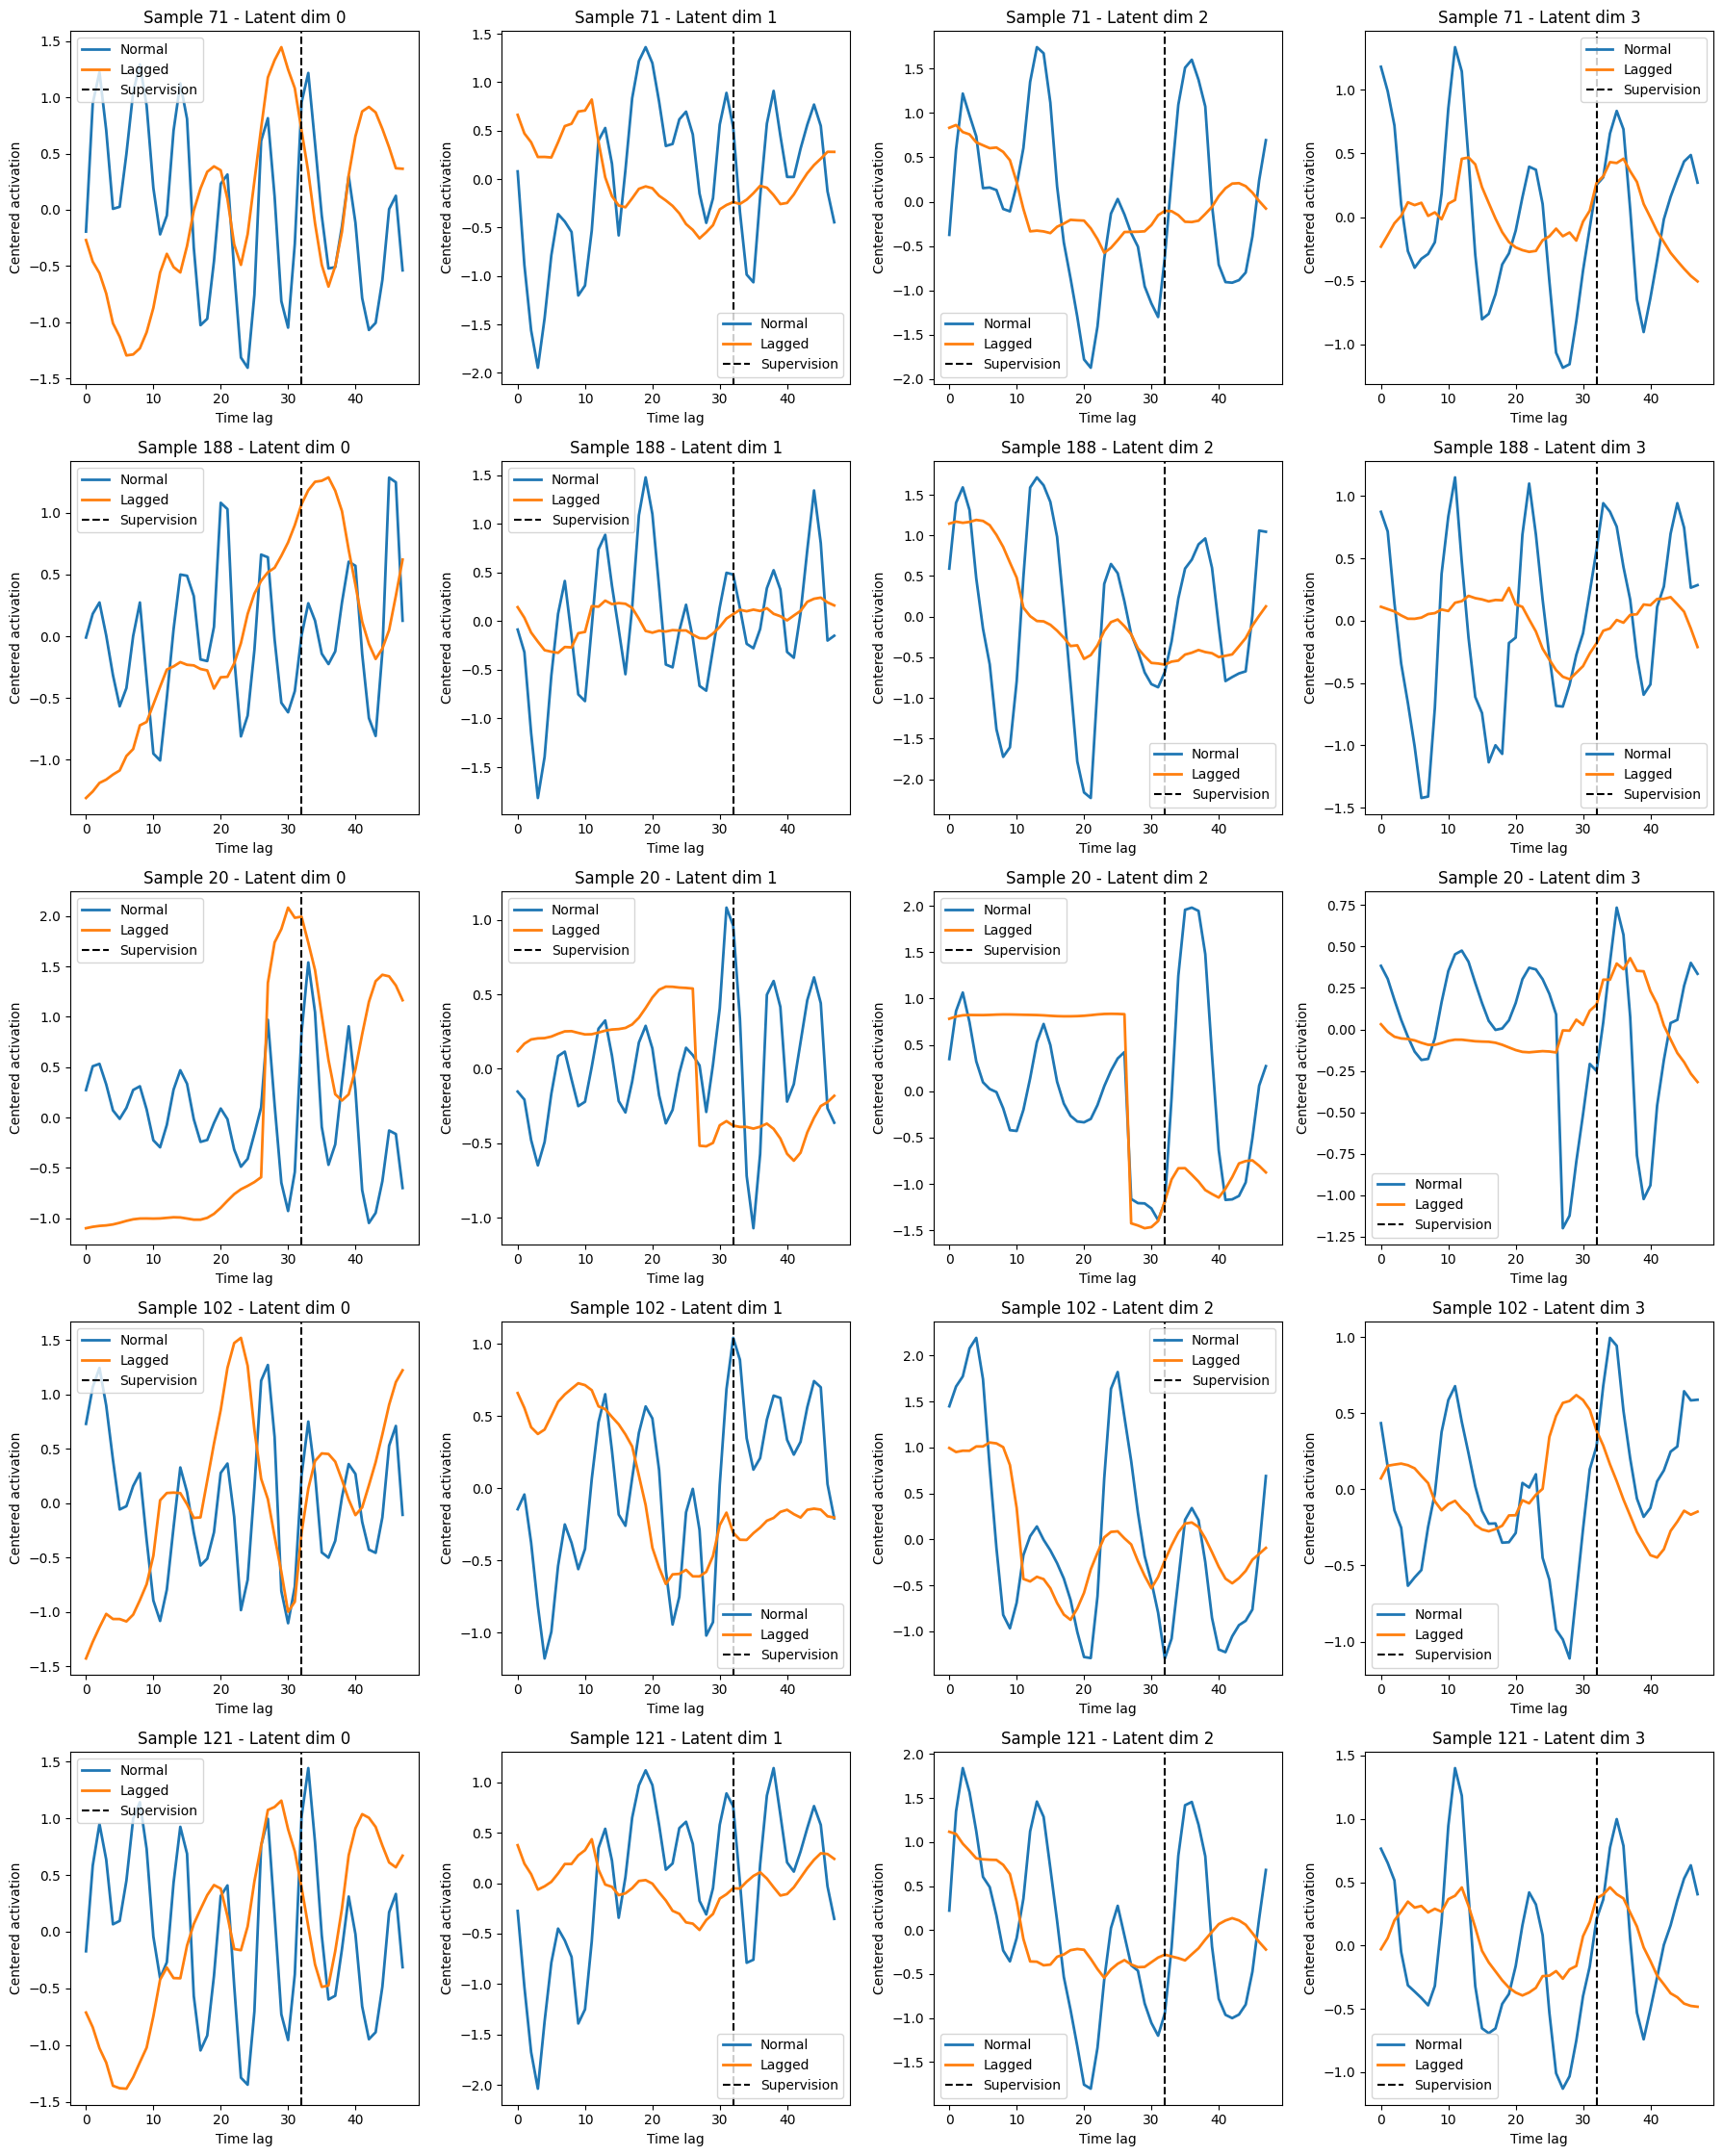

In [40]:
H_normal = get_embeddings(normal_shred, test_dataset, device)
H_lagged = get_embeddings(lagged_shred, test_dataset, device)

print("H_normal shape:", H_normal.shape)  # (lags, n_samples, hidden_size)
print("H_lagged shape:", H_lagged.shape)  # (lags, n_samples, hidden_size)

H_normal = np.transpose(H_normal, (1, 0, 2))
H_lagged = np.transpose(H_lagged, (1, 0, 2))

print("H_normal permuted shape:", H_normal.shape)  # (n_samples, lags, hidden_size)
print("H_lagged permuted shape:", H_lagged.shape)  # (n_samples, lags, hidden_size)

H_normal_centered = H_normal - H_normal.mean(axis=1, keepdims=True)
H_lagged_centered = H_lagged - H_lagged.mean(axis=1, keepdims=True)

plot_temporal_embeddings(H_normal_centered, H_lagged_centered)

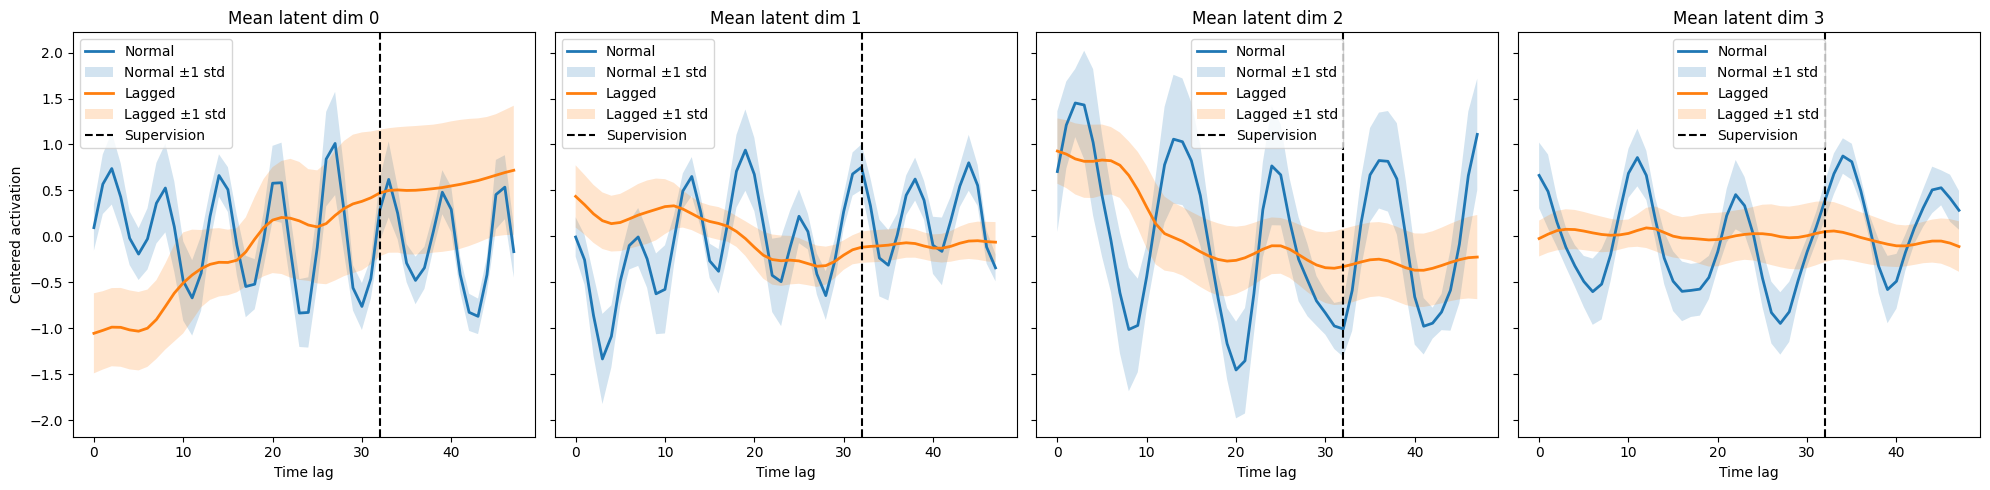

In [28]:
plot_temporal_embeddings_mean(H_normal_centered, H_lagged_centered)

In [29]:
stats, tv_normal, tv_lagged = compute_tv_stats(H_normal, H_lagged)

print("Normal  TV:  ", stats["normal_mean"], "±", stats["normal_std"])
print("Lagged  TV:  ", stats["lagged_mean"], "±", stats["lagged_std"])

Normal  TV:   70.55206 ± 11.844952
Lagged  TV:   33.595726 ± 7.2532144


## Hyperparameter tuning

In [ ]:
# Rebuild the lagged datasets once, then sweep all lagged-loss configurations
ERRORS = []

manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements_av)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = False, pad_output=True)

nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

for config in LAGGED_LOSS_TUNING_GRID:
    w_factor = config["w_factor"]
    w_keeped_timesteps = config["w_keeped_timesteps"]
    print("\n" + "="*100)
    print(f"\nRunning lagged training with w_factor={w_factor} and w_keeped_timesteps={w_keeped_timesteps}")

    model_args = dict(
        # Encoder
        encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
        dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels = False,
        # Decoder
        decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, decoder_3D = True
    )
    mshred = mSHRED(args=model_args).to(device)

    train_errors, valid_errors = lagged_fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=False,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, w_factor=w_factor, w_keeped_steps=w_keeped_timesteps
    )

    test_error = evaluate_model(
        lagged_evaluate, mshred, train_dataset, val_dataset, test_dataset,
        model=f"(mSHRED): TR+{DECODER}", type=f"Lagged_training (w={w_factor}, k={w_keeped_timesteps})"
    )

    ERRORS.append(test_error)
    dataframe_errors = pd.DataFrame(ERRORS).sort_values(by="test-mre")
    display(dataframe_errors)
    dataframe_errors.to_csv("dataframe_errors.csv", index=False)

    del mshred, model_args, train_errors, valid_errors, test_error

Residual energy of Surface elevation after keeping 12 modes: 0.1701 %
Residual energy of U velocity after keeping 40 modes: 0.2161 %
Residual energy of V velocity after keeping 68 modes: 0.1971 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Input shape for the model: 5
Output shape for the model: 120


Running lagged training with w_factor=0.2 and w_keeped_timesteps=4
Starting training...
Training completed with best validation loss: 0.0052


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=4)",0.003809,0.005172,0.003325,0.125335,0.135687,0.119291




Running lagged training with w_factor=0.2 and w_keeped_timesteps=8
Starting training...
Training completed with best validation loss: 0.0050


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
1,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=8)",0.003623,0.005000,0.003233,0.122229,0.133399,0.117192
0,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=4)",0.003809,0.005172,0.003325,0.125335,0.135687,0.119291




Running lagged training with w_factor=0.2 and w_keeped_timesteps=12
Starting training...
Training completed with best validation loss: 0.0052


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
1,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=8)",0.003623,0.005000,0.003233,0.122229,0.133399,0.117192
2,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=12)",0.003622,0.005161,0.003257,0.122473,0.135643,0.117982
0,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=4)",0.003809,0.005172,0.003325,0.125335,0.135687,0.119291


... (60 outputs left out)



Running lagged training with w_factor=0.8 and w_keeped_timesteps=16
Starting training...
Training completed with best validation loss: 0.0050


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
28,(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=16)",0.003401,0.005074,0.003164,0.118862,0.133322,0.115688
17,(mSHRED): TR+cnn,"Lagged_training (w=0.5, k=12)",0.003341,0.005103,0.003195,0.117868,0.133682,0.115747
33,(mSHRED): TR+cnn,"Lagged_training (w=0.8, k=16)",0.003476,0.004995,0.003175,0.119815,0.133521,0.115812
10,(mSHRED): TR+cnn,"Lagged_training (w=0.4, k=4)",0.003558,0.005100,0.003172,0.121419,0.134063,0.116187
21,(mSHRED): TR+cnn,"Lagged_training (w=0.6, k=8)",0.003472,0.005105,0.003218,0.119817,0.133981,0.116340
3,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=16)",0.003522,0.005085,0.003238,0.120794,0.132999,0.116734
29,(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=20)",0.003466,0.005013,0.003212,0.120146,0.133054,0.116912
19,(mSHRED): TR+cnn,"Lagged_training (w=0.5, k=20)",0.003585,0.005034,0.003218,0.121704,0.133732,0.116988
9,(mSHRED): TR+cnn,"Lagged_training (w=0.3, k=20)",0.003599,0.005126,0.003215,0.121952,0.134830,0.117066
14,(mSHRED): TR+cnn,"Lagged_training (w=0.4, k=20)",0.003656,0.005169,0.003237,0.122739,0.135053,0.117190




Running lagged training with w_factor=0.8 and w_keeped_timesteps=20
Starting training...
Training completed with best validation loss: 0.0050


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
28,(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=16)",0.003401,0.005074,0.003164,0.118862,0.133322,0.115688
17,(mSHRED): TR+cnn,"Lagged_training (w=0.5, k=12)",0.003341,0.005103,0.003195,0.117868,0.133682,0.115747
33,(mSHRED): TR+cnn,"Lagged_training (w=0.8, k=16)",0.003476,0.004995,0.003175,0.119815,0.133521,0.115812
10,(mSHRED): TR+cnn,"Lagged_training (w=0.4, k=4)",0.003558,0.005100,0.003172,0.121419,0.134063,0.116187
21,(mSHRED): TR+cnn,"Lagged_training (w=0.6, k=8)",0.003472,0.005105,0.003218,0.119817,0.133981,0.116340
3,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=16)",0.003522,0.005085,0.003238,0.120794,0.132999,0.116734
34,(mSHRED): TR+cnn,"Lagged_training (w=0.8, k=20)",0.003637,0.005030,0.003222,0.122616,0.133592,0.116885
29,(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=20)",0.003466,0.005013,0.003212,0.120146,0.133054,0.116912
19,(mSHRED): TR+cnn,"Lagged_training (w=0.5, k=20)",0.003585,0.005034,0.003218,0.121704,0.133732,0.116988
9,(mSHRED): TR+cnn,"Lagged_training (w=0.3, k=20)",0.003599,0.005126,0.003215,0.121952,0.134830,0.117066


## Results

In [6]:
dataframe_errors = pd.read_csv("results_df/notebook7/dataframe_errors.csv")
print("\nFinal comparison of all models, ordered by test MRE:")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)


Final comparison of all models, ordered by test MRE:


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
1,(mSHRED): TR+cnn,Lagged_training,0.003951,0.005348,0.003345,0.127063,0.137101,0.119715
0,(mSHRED): TR+cnn,Normal_training,0.004165,0.005355,0.003379,0.129648,0.136465,0.120205


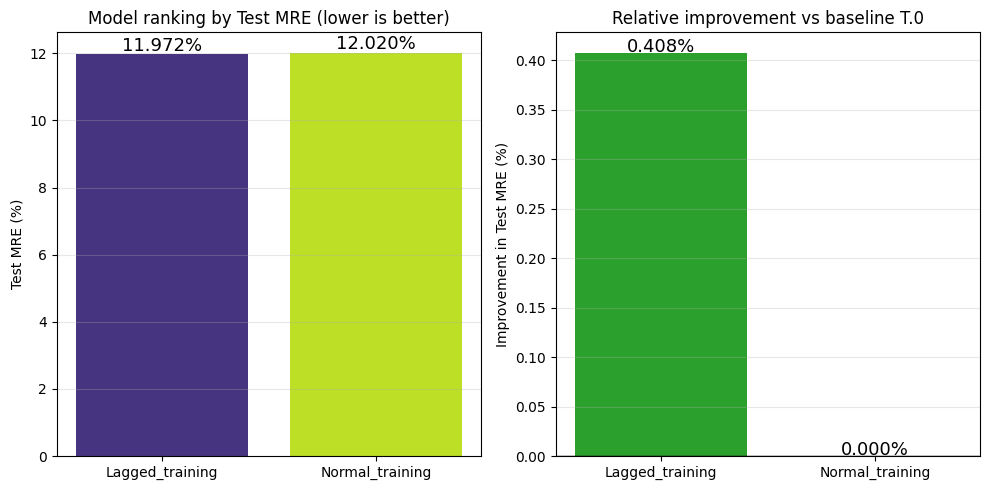

In [7]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].bar(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_ylabel("Test MRE (%)")
axes[0].grid(axis="y", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(i, v+0.1, f"{v:.3f}%", ha="center", fontsize=13)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].bar(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_ylabel("Improvement in Test MRE (%)")
axes[1].grid(axis="y", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(i, v+0.001, f"{v:.3f}%", ha="center", fontsize=13)

plt.tight_layout()
plt.show()

## Results Tuning

In [10]:
dataframe_errors = pd.read_csv("results_df/notebook7/dataframe_errors_all2.csv")
print("\nFinal comparison of all models, ordered by test MRE:")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)


Final comparison of all models, ordered by test MRE:


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
30,(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=16)",0.003401,0.005074,0.003164,0.118862,0.133322,0.115688
19,(mSHRED): TR+cnn,"Lagged_training (w=0.5, k=12)",0.003341,0.005103,0.003195,0.117868,0.133682,0.115747
35,(mSHRED): TR+cnn,"Lagged_training (w=0.8, k=16)",0.003476,0.004995,0.003175,0.119815,0.133521,0.115812
12,(mSHRED): TR+cnn,"Lagged_training (w=0.4, k=4)",0.003558,0.005100,0.003172,0.121419,0.134063,0.116187
37,(mSHRED): TR+cnn,"Lagged_training (w=0.6, k=4)",0.003528,0.005074,0.003185,0.120757,0.133762,0.116195
...,...,...,...,...,...,...,...,...
51,(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=4)",0.003888,0.005174,0.003323,0.126664,0.136109,0.119458
15,(mSHRED): TR+cnn,"Lagged_training (w=0.4, k=16)",0.003950,0.005258,0.003337,0.127374,0.137112,0.119575
28,(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=8)",0.003875,0.005168,0.003351,0.126518,0.136517,0.119766
24,(mSHRED): TR+cnn,"Lagged_training (w=0.6, k=12)",0.003893,0.005108,0.003372,0.126410,0.135433,0.120141


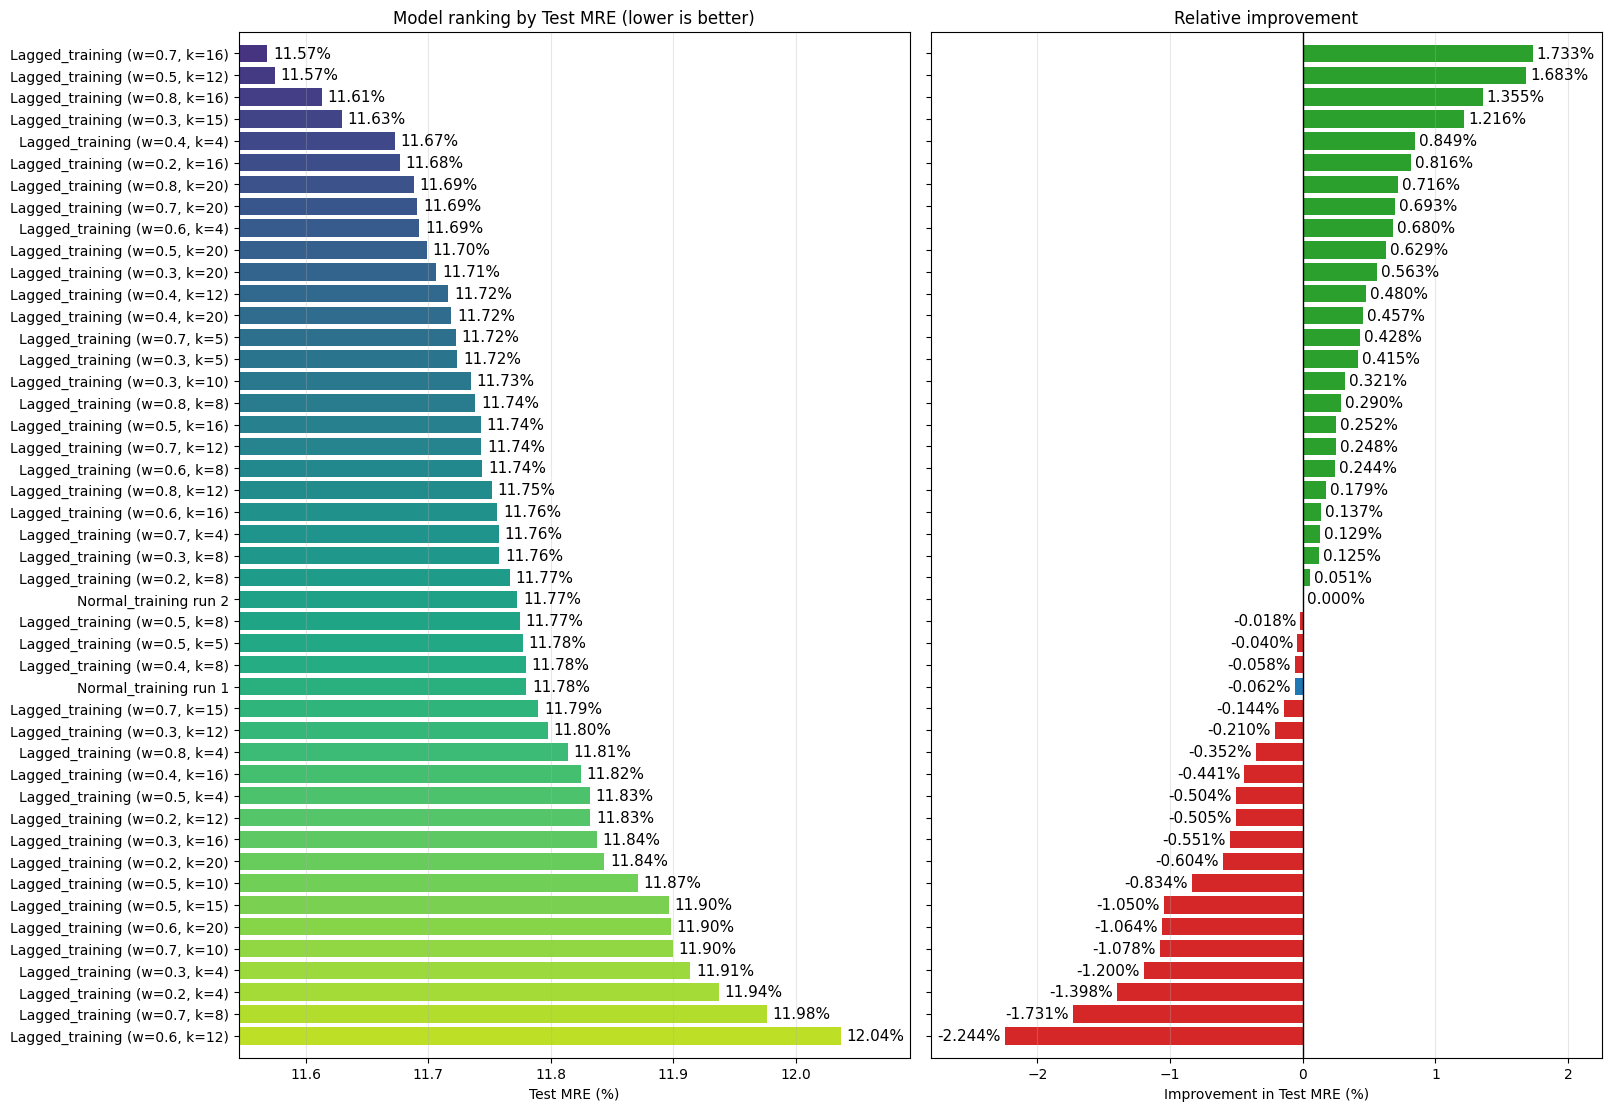

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Meaningful summary plot: ranking + improvement vs baseline
numeric_cols = dataframe_errors.select_dtypes(include=[np.number]).columns.tolist()
df_plot = dataframe_errors.groupby("type", as_index=False)[numeric_cols].mean()
df_plot = df_plot.sort_values("test-mre").reset_index(drop=True)

# Baseline = Normal_training (average if duplicates exist)
baseline_mask = df_plot["type"].str.contains("Normal_training", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

# Keeping height at 11 for a balanced look with the new padding
fig, axes = plt.subplots(1, 2, figsize=(16, 11), constrained_layout=True)

num_rows = len(df_plot)
y_positions = np.arange(num_rows)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, num_rows))
axes[0].barh(y_positions, df_plot["test-mre_%"], color=colors)
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(df_plot["type"])
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

# ADJUSTMENT: Changed padding from 0.5 to 1.0 to add a subtle sliver of white space
axes[0].set_ylim(num_rows, -1.0)

# Dynamic x limits based on actual range
min_mre = df_plot["test-mre_%"].min()
max_mre = df_plot["test-mre_%"].max()
axes[0].set_xlim(min_mre - (max_mre - min_mre) * 0.05, max_mre + (max_mre - min_mre) * 0.12)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + (max_mre - min_mre) * 0.01, i, f"{v:.2f}%", va="center", fontsize=11)

# --- Right: Improvement ---
imp_colors = ["tab:blue" if ("Normal_training" in t) else ("tab:green" if x >= 0 else "tab:red") for t, x in zip(df_plot["type"], df_plot["improvement_vs_T0_%"])]
axes[1].barh(y_positions, df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

# ADJUSTMENT: Mirror the exact same slight padding on the right plot
axes[1].set_ylim(num_rows, -1.0)

# Balanced x limits with proper padding for text labels
min_imp = df_plot["improvement_vs_T0_%"].min()
max_imp = df_plot["improvement_vs_T0_%"].max()
axes[1].set_xlim(min_imp * 1.25, max_imp * 1.3)

axes[1].set_yticklabels([])
axes[1].set_yticks(y_positions)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    if v >= 0:
        axes[1].text(v + 0.03, i, f"{v:.3f}%", va="center", ha="left", fontsize=11)
    else:
        axes[1].text(v - 0.03, i, f"{v:.3f}%", va="center", ha="right", fontsize=11)

plt.show()

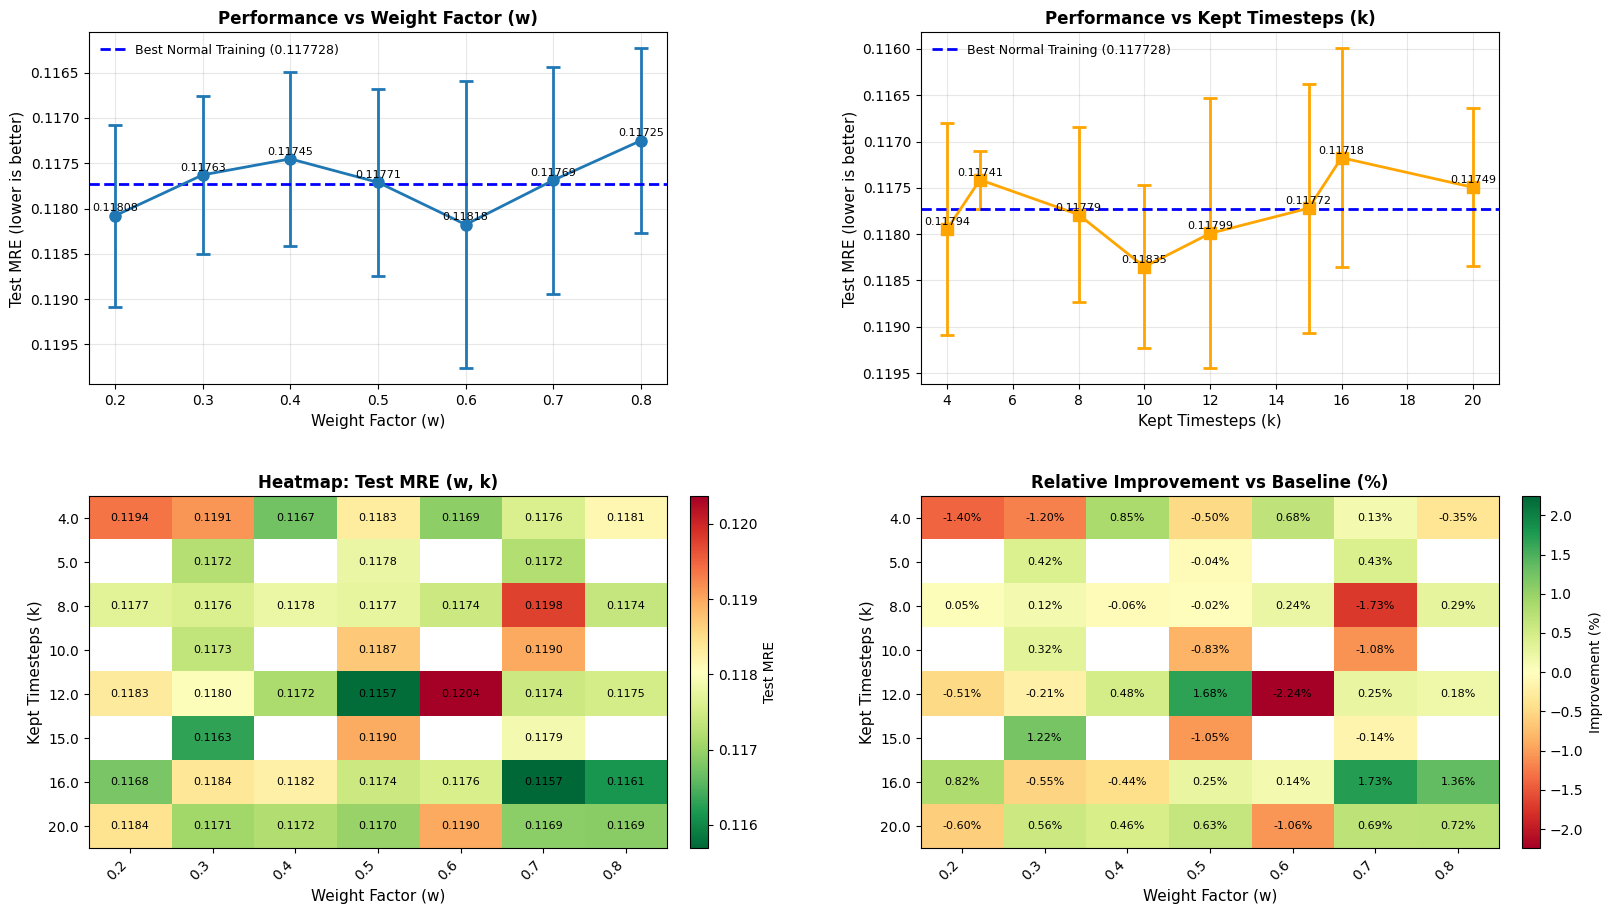

In [12]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Extract w and k values from lagged training results
df_tuning = dataframe_errors[dataframe_errors["type"].str.contains("Lagged_training \(w=", regex=True)].copy()

# Parse w and k from type string
def extract_w_k(type_str):
    match = re.search(r"w=([\d.]+),\s*k=(\d+)", type_str)
    if match:
        return float(match.group(1)), int(match.group(2))
    return None, None

df_tuning[["w", "k"]] = df_tuning["type"].apply(lambda x: pd.Series(extract_w_k(x)))

# Get best normal training baseline
normal_mask = dataframe_errors["type"].str.contains("Normal_training", regex=False)
best_normal_test_mre = dataframe_errors.loc[normal_mask, "test-mre"].min() if normal_mask.any() else None

# --- Plot Setup ---
fig, axes = plt.subplots(2, 2, figsize=(16, 9), constrained_layout=True)
axes = axes.flatten()
fig.set_constrained_layout_pads(w_pad=0.03, h_pad=0.03, wspace=0.08, hspace=0.10)

# --- Plot 1: w vs performance (aggregated across k) ---
w_perf = df_tuning.groupby("w")["test-mre"].agg(["mean", "std"])
axes[0].errorbar(w_perf.index, w_perf["mean"], yerr=w_perf["std"], marker="o", linewidth=2, markersize=8, capsize=5, capthick=2)
if best_normal_test_mre is not None:
    axes[0].axhline(best_normal_test_mre, color="blue", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")
axes[0].set_xlabel("Weight Factor (w)", fontsize=11)
axes[0].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[0].set_title("Performance vs Weight Factor (w)", fontsize=12, fontweight="bold")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=9, loc="best", frameon=False)

# FIX: Invert y-axis so lower MRE values are visually at the top
axes[0].invert_yaxis()

for w_val, mean_val in zip(w_perf.index, w_perf["mean"]):
    axes[0].text(w_val, mean_val - w_perf["std"].max() * 0.03, f"{mean_val:.5f}", ha="center", fontsize=8)

# --- Plot 2: k vs performance (aggregated across w) ---
k_perf = df_tuning.groupby("k")["test-mre"].agg(["mean", "std"])
axes[1].errorbar(k_perf.index, k_perf["mean"], yerr=k_perf["std"], marker="s", linewidth=2, markersize=8, capsize=5, capthick=2, color="orange")
if best_normal_test_mre is not None:
    axes[1].axhline(best_normal_test_mre, color="blue", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")
axes[1].set_xlabel("Kept Timesteps (k)", fontsize=11)
axes[1].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[1].set_title("Performance vs Kept Timesteps (k)", fontsize=12, fontweight="bold")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=9, loc="best", frameon=False)

# FIX: Invert y-axis so lower MRE values are visually at the top
axes[1].invert_yaxis()

for k_val, mean_val in zip(k_perf.index, k_perf["mean"]):
    axes[1].text(k_val, mean_val - k_perf["std"].max() * 0.03, f"{mean_val:.5f}", ha="center", fontsize=8)

# --- Plot 3: Heatmap of w-k combinations (Test MRE) ---
pivot_table = df_tuning.pivot_table(values="test-mre", index="k", columns="w", aggfunc="mean")
pivot_table = pivot_table.sort_index(ascending=True)
masked_data = np.ma.masked_invalid(pivot_table.values)

im = axes[2].imshow(masked_data, cmap="RdYlGn_r", aspect="auto")
axes[2].set_xticks(range(len(pivot_table.columns)))
axes[2].set_yticks(range(len(pivot_table.index)))
axes[2].set_xticklabels([f"{w:.1f}" for w in pivot_table.columns], rotation=45, ha="right")
axes[2].set_yticklabels([f"{k}" for k in pivot_table.index])
axes[2].set_xlabel("Weight Factor (w)", fontsize=11)
axes[2].set_ylabel("Kept Timesteps (k)", fontsize=11)
axes[2].set_title("Heatmap: Test MRE (w, k)", fontsize=12, fontweight="bold")

for i in range(len(pivot_table.index)):
    for j in range(len(pivot_table.columns)):
        val = pivot_table.values[i, j]
        if not np.isnan(val):
            axes[2].text(j, i, f"{val:.4f}", ha="center", va="center", fontsize=8, color="black")

cbar = fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
cbar.set_label("Test MRE", fontsize=10)

# --- Plot 4: Heatmap of relative improvement vs baseline ---
if best_normal_test_mre is not None:
    df_tuning["improvement"] = (best_normal_test_mre - df_tuning["test-mre"]) / best_normal_test_mre * 100
    
    improvement_pivot = df_tuning.pivot_table(values="improvement", index="k", columns="w", aggfunc="mean")
    improvement_pivot = improvement_pivot.sort_index(ascending=True)
    
    masked_improvement = np.ma.masked_invalid(improvement_pivot.values)
    max_abs_improvement = np.nanmax(np.abs(improvement_pivot.values))
    
    im4 = axes[3].imshow(masked_improvement, cmap="RdYlGn", aspect="auto", 
                         vmin=-max_abs_improvement, vmax=max_abs_improvement)
    axes[3].set_xticks(range(len(improvement_pivot.columns)))
    axes[3].set_yticks(range(len(improvement_pivot.index)))
    axes[3].set_xticklabels([f"{w:.1f}" for w in improvement_pivot.columns], rotation=45, ha="right")
    axes[3].set_yticklabels([f"{k}" for k in improvement_pivot.index])
    axes[3].set_xlabel("Weight Factor (w)", fontsize=11)
    axes[3].set_ylabel("Kept Timesteps (k)", fontsize=11)
    axes[3].set_title("Relative Improvement vs Baseline (%)", fontsize=12, fontweight="bold")
    
    for i in range(len(improvement_pivot.index)):
        for j in range(len(improvement_pivot.columns)):
            val = improvement_pivot.values[i, j]
            if not np.isnan(val):
                axes[3].text(j, i, f"{val:.2f}%", ha="center", va="center", fontsize=8, color="black")
    
    cbar4 = fig.colorbar(im4, ax=axes[3], fraction=0.046, pad=0.04)
    cbar4.set_label("Improvement (%)", fontsize=10)

plt.show()

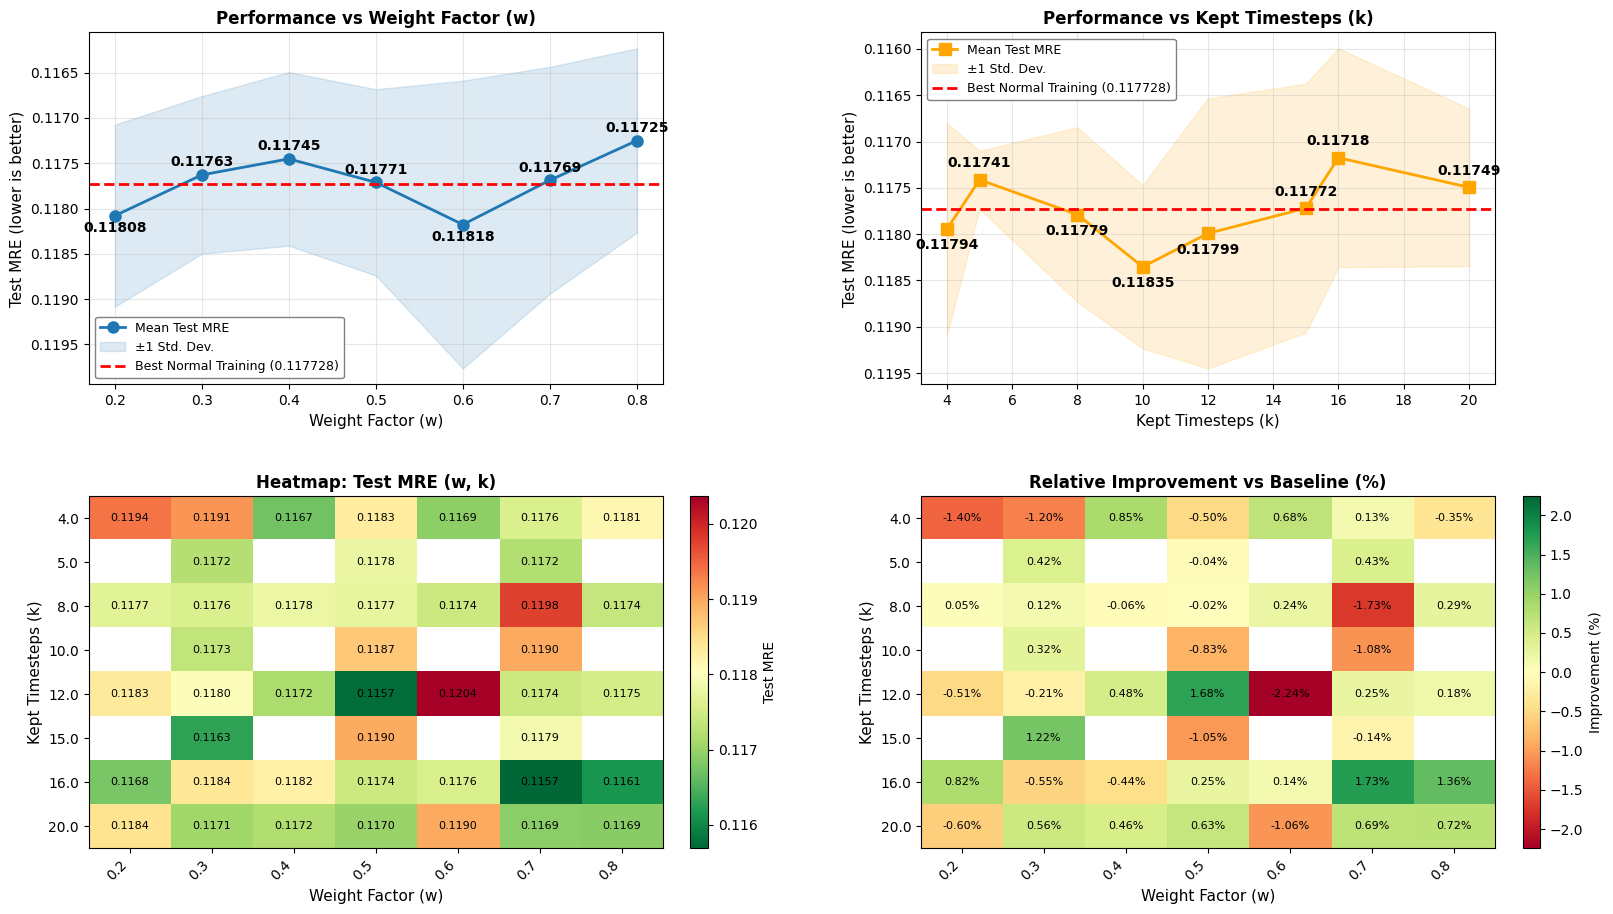

In [13]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Extract w and k values from lagged training results
df_tuning = dataframe_errors[dataframe_errors["type"].str.contains("Lagged_training \(w=", regex=True)].copy()

# Parse w and k from type string
def extract_w_k(type_str):
    match = re.search(r"w=([\d.]+),\s*k=(\d+)", type_str)
    if match:
        return float(match.group(1)), int(match.group(2))
    return None, None

df_tuning[["w", "k"]] = df_tuning["type"].apply(lambda x: pd.Series(extract_w_k(x)))

# Get best normal training baseline
normal_mask = dataframe_errors["type"].str.contains("Normal_training", regex=False)
best_normal_test_mre = dataframe_errors.loc[normal_mask, "test-mre"].min() if normal_mask.any() else None

# --- Plot Setup ---
fig, axes = plt.subplots(2, 2, figsize=(16, 9), constrained_layout=True)
axes = axes.flatten()
fig.set_constrained_layout_pads(w_pad=0.03, h_pad=0.03, wspace=0.08, hspace=0.10)

# --- Plot 1: w vs performance (aggregated across k) ---
w_perf = df_tuning.groupby("w")["test-mre"].agg(["mean", "std"])

axes[0].plot(w_perf.index, w_perf["mean"], marker="o", linewidth=2, markersize=8, color="tab:blue", label="Mean Test MRE")
axes[0].fill_between(w_perf.index, w_perf["mean"] - w_perf["std"], w_perf["mean"] + w_perf["std"], 
                     color="tab:blue", alpha=0.15, label="±1 Std. Dev.")

if best_normal_test_mre is not None:
    axes[0].axhline(best_normal_test_mre, color="red", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")

axes[0].set_xlabel("Weight Factor (w)", fontsize=11)
axes[0].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[0].set_title("Performance vs Weight Factor (w)", fontsize=12, fontweight="bold")
axes[0].grid(alpha=0.3)

# FIX: Added solid white background with a subtle border to the legend
axes[0].legend(fontsize=9, loc="best", frameon=True, facecolor="white", edgecolor="gray", framealpha=1.0)
axes[0].invert_yaxis()

offset_w = (w_perf["mean"].max() - w_perf["mean"].min()) * 0.15
for w_val, mean_val in zip(w_perf.index, w_perf["mean"]):
    if best_normal_test_mre is not None and mean_val < best_normal_test_mre:
        y_pos = mean_val - offset_w
    else:
        y_pos = mean_val + offset_w
    axes[0].text(w_val, y_pos, f"{mean_val:.5f}", ha="center", va="center", fontsize=10, fontweight="bold")

# --- Plot 2: k vs performance (aggregated across w) ---
k_perf = df_tuning.groupby("k")["test-mre"].agg(["mean", "std"])

axes[1].plot(k_perf.index, k_perf["mean"], marker="s", linewidth=2, markersize=8, color="orange", label="Mean Test MRE")
axes[1].fill_between(k_perf.index, k_perf["mean"] - k_perf["std"], k_perf["mean"] + k_perf["std"], 
                     color="orange", alpha=0.15, label="±1 Std. Dev.")

if best_normal_test_mre is not None:
    axes[1].axhline(best_normal_test_mre, color="red", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")

axes[1].set_xlabel("Kept Timesteps (k)", fontsize=11)
axes[1].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[1].set_title("Performance vs Kept Timesteps (k)", fontsize=12, fontweight="bold")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=9, loc="best", frameon=True, facecolor="white", edgecolor="gray", framealpha=1.0)
axes[1].invert_yaxis()

# FIX: Added fontweight="bold" to match plot 1
offset_k = (k_perf["mean"].max() - k_perf["mean"].min()) * 0.15
for k_val, mean_val in zip(k_perf.index, k_perf["mean"]):
    if best_normal_test_mre is not None and mean_val < best_normal_test_mre:
        y_pos = mean_val - offset_k
    else:
        y_pos = mean_val + offset_k
    axes[1].text(k_val, y_pos, f"{mean_val:.5f}", ha="center", va="center", fontsize=10, fontweight="bold")

# --- Plot 3: Heatmap of w-k combinations (Test MRE) ---
pivot_table = df_tuning.pivot_table(values="test-mre", index="k", columns="w", aggfunc="mean")
pivot_table = pivot_table.sort_index(ascending=True)
masked_data = np.ma.masked_invalid(pivot_table.values)

im = axes[2].imshow(masked_data, cmap="RdYlGn_r", aspect="auto")
axes[2].set_xticks(range(len(pivot_table.columns)))
axes[2].set_yticks(range(len(pivot_table.index)))
axes[2].set_xticklabels([f"{w:.1f}" for w in pivot_table.columns], rotation=45, ha="right")
axes[2].set_yticklabels([f"{k}" for k in pivot_table.index])
axes[2].set_xlabel("Weight Factor (w)", fontsize=11)
axes[2].set_ylabel("Kept Timesteps (k)", fontsize=11)
axes[2].set_title("Heatmap: Test MRE (w, k)", fontsize=12, fontweight="bold")

for i in range(len(pivot_table.index)):
    for j in range(len(pivot_table.columns)):
        val = pivot_table.values[i, j]
        if not np.isnan(val):
            axes[2].text(j, i, f"{val:.4f}", ha="center", va="center", fontsize=8, color="black")

cbar = fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
cbar.set_label("Test MRE", fontsize=10)

# --- Plot 4: Heatmap of relative improvement vs baseline ---
if best_normal_test_mre is not None:
    df_tuning["improvement"] = (best_normal_test_mre - df_tuning["test-mre"]) / best_normal_test_mre * 100
    
    improvement_pivot = df_tuning.pivot_table(values="improvement", index="k", columns="w", aggfunc="mean")
    improvement_pivot = improvement_pivot.sort_index(ascending=True)
    
    masked_improvement = np.ma.masked_invalid(improvement_pivot.values)
    max_abs_improvement = np.nanmax(np.abs(improvement_pivot.values))
    
    im4 = axes[3].imshow(masked_improvement, cmap="RdYlGn", aspect="auto", 
                         vmin=-max_abs_improvement, vmax=max_abs_improvement)
    axes[3].set_xticks(range(len(improvement_pivot.columns)))
    axes[3].set_yticks(range(len(improvement_pivot.index)))
    axes[3].set_xticklabels([f"{w:.1f}" for w in improvement_pivot.columns], rotation=45, ha="right")
    axes[3].set_yticklabels([f"{k}" for k in improvement_pivot.index])
    axes[3].set_xlabel("Weight Factor (w)", fontsize=11)
    axes[3].set_ylabel("Kept Timesteps (k)", fontsize=11)
    axes[3].set_title("Relative Improvement vs Baseline (%)", fontsize=12, fontweight="bold")
    
    for i in range(len(improvement_pivot.index)):
        for j in range(len(improvement_pivot.columns)):
            val = improvement_pivot.values[i, j]
            if not np.isnan(val):
                axes[3].text(j, i, f"{val:.2f}%", ha="center", va="center", fontsize=8, color="black")
    
    cbar4 = fig.colorbar(im4, ax=axes[3], fraction=0.046, pad=0.04)
    cbar4.set_label("Improvement (%)", fontsize=10)

plt.show()